# Notebook 02 - exploratory data analysis
What does the clean data look like, and is there visible evidence of a regime shift in 2026 before we train anything? Reads `data/clean_laps.csv.gz` from notebook 01.

In [1]:
import os, sys
# Run from the repo root so data/, figures/ and results/ resolve, and make src/ importable.
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1lap.features import add_features

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEASONS = [2022, 2023, 2024, 2025, 2026]
df = add_features(pd.read_csv('data/clean_laps.csv.gz'))   # adds circuit / team lineage for grouping
df.shape

(89737, 24)

### 1. Target distribution by season

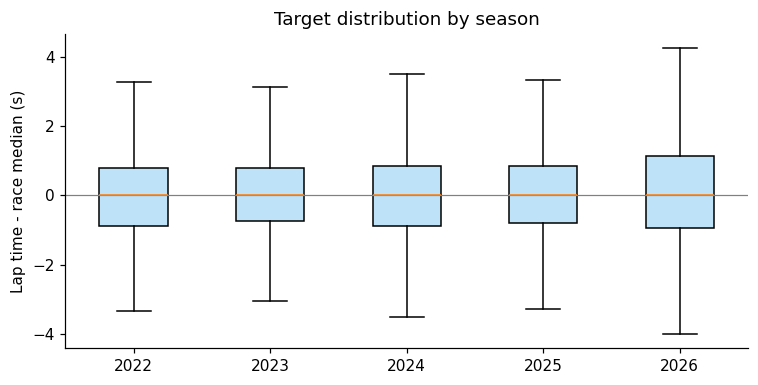

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.6))
data = [df.loc[df.season == y, 'lap_delta_s'] for y in SEASONS]
ax.boxplot(data, tick_labels=SEASONS, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#bee3f8'))
ax.axhline(0, color='grey', lw=.8); ax.set_ylabel('Lap time - race median (s)'); ax.set_title('Target distribution by season')
plt.tight_layout(); plt.savefig('figures/02_target_by_season.png', dpi=150); plt.show()

**Figure 02.** 2022-2025 look almost identical: centred on zero with an interquartile range of about 1.6-1.8 s. 2026 is visibly wider (~2.1 s), especially on the slow side (the upper box and whisker stretch further). So in 2026 the field is more spread out within a race: the gap between the fastest and slowest laps grew, which is what you'd expect if the new cars separated the teams more.

### 2. Within-stint pace: 2025 vs 2026

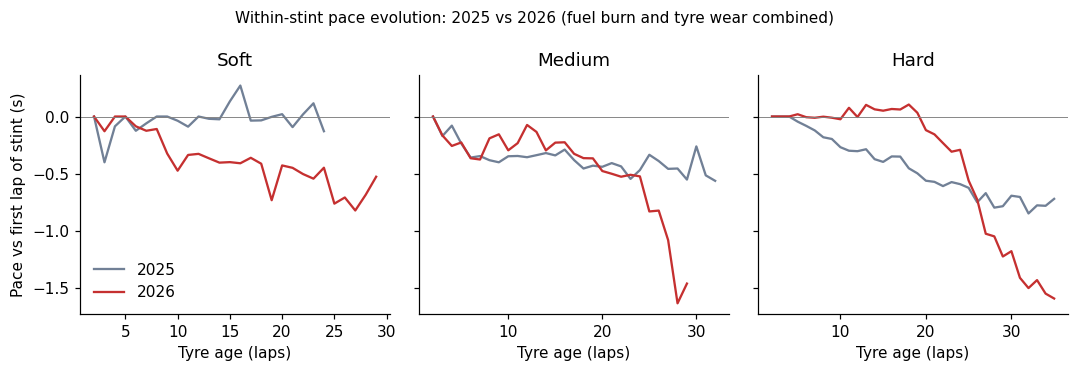

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
colors = {2025: '#718096', 2026: '#c53030'}
for ax, cmp in zip(axs, ['SOFT', 'MEDIUM', 'HARD']):
    for y in [2025, 2026]:
        s = df[(df.season == y) & (df.compound == cmp) & (df.tyre_age <= 35)]
        # within-stint pace change: delta relative to the stint's first clean lap
        s = s.assign(rel=s.lap_delta_s - s.groupby(['event', 'driver', 'stint']).lap_delta_s.transform('first'))
        g = s.groupby('tyre_age').rel.median(); n = s.groupby('tyre_age').size(); g = g[n >= 50]
        ax.plot(g.index, g.values, color=colors[y], label=str(y))
    ax.set_title(cmp.title()); ax.set_xlabel('Tyre age (laps)'); ax.axhline(0, color='grey', lw=.6)
axs[0].set_ylabel('Pace vs first lap of stint (s)'); axs[0].legend(frameon=False)
fig.suptitle('Within-stint pace evolution: 2025 vs 2026 (fuel burn and tyre wear combined)', fontsize=10)
plt.tight_layout(); plt.savefig('figures/03_stint_pace_2025_vs_2026.png', dpi=150); plt.show()

**Figure 03.** In 2025, laps get steadily faster through a stint as fuel burns off (the fuel gain outweighs tyre wear). In 2026 the hard-tyre stints stay flat for about 18 laps and then speed up much more sharply. That could be 2026 energy management (drivers harvesting and lifting early in a stint), but it may also be a **composition effect**: only some stints run that long, and they're not a random sample. Fuel burn and tyre age also rise together lap by lap, so this plot shows their combined effect, not each one separately. Notebook 07 tries to pull them apart.

### 3. Absolute pace change by circuit

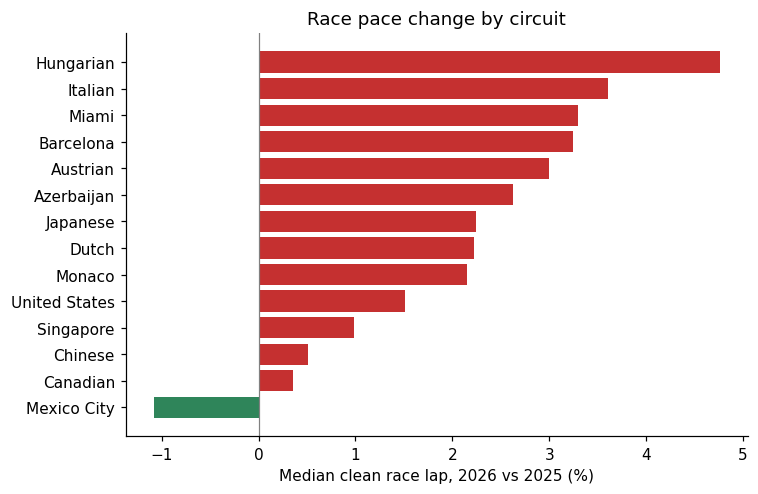

14 circuits raced dry in both years; median change 2.23%


In [4]:
med = df.groupby(['season', 'circuit']).race_median_s.first().unstack(0)
common = med[[2025, 2026]].dropna(); common['change_s'] = common[2026] - common[2025]
common['change_%'] = (common.change_s / common[2025] * 100).round(2)
common = common.sort_values('change_%')
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(common.index, common['change_%'], color=np.where(common['change_%'] > 0, '#c53030', '#2f855a'))
ax.axvline(0, color='grey', lw=.8); ax.set_xlabel('Median clean race lap, 2026 vs 2025 (%)'); ax.set_title('Race pace change by circuit')
plt.tight_layout(); plt.savefig('figures/04_pace_change_by_circuit.png', dpi=150); plt.show()
print(f'{len(common)} circuits raced dry in both years; median change {common["change_%"].median():.2f}%')

**Figure 04.** On almost every circuit raced dry in both years, the 2026 median race lap is slower than 2025, by about 2% at the median, with Mexico City the one exception. This absolute slowdown is invisible to our model on purpose, because the target subtracts each race's median, so the model only sees *relative* pace (who's faster than whom, and how pace evolves through a stint). We report the absolute change here so it isn't lost.